## Step 1: Import Libraries and Load Data

**Objective:** Import the required Python libraries and load the applicants, interns, and hackathon scores tables from the SQLite database.

**Description:** We will use Pandas to handle data, SQLite to connect to our database, and Matplotlib to create visualizations. The three tables will be loaded into separate DataFrames.

**Expected Outcome:** Three DataFrames will be available for dashboard development.

In [1]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt


In [2]:
# Connect to database
conn = sqlite3.connect("nextgen.db")

In [3]:
# Load tables
applicants = pd.read_sql_query("SELECT * FROM applicants", conn)
interns = pd.read_sql_query("SELECT * FROM interns", conn)
scores = pd.read_sql_query("SELECT * FROM hackathon_scores", conn)

conn.close()

In [4]:
# Rename column for easier use
applicants.rename(
    columns={"Domain Applied": "domain"},
    inplace=True
)

In [5]:
print("Applicants:", applicants.shape)
print("Interns:", interns.shape)
print("Hackathon Scores:", scores.shape)

Applicants: (73, 8)
Interns: (23, 5)
Hackathon Scores: (20, 3)


## Step 2: Create an Interactive Domain Filter

**Objective:** Create a domain filter to allow users to view applicants from a specific domain.

**Description:** We will use a dropdown menu to display all available domains. The selected domain will be used to filter the applicants DataFrame. Selecting "All" will display all applicants.

**Expected Outcome:** A domain dropdown will be created, and the applicant data will be filtered according to the selected domain.

In [6]:
# Get all unique domains
domain_list = ['All'] + sorted(applicants['domain'].unique().tolist())

In [7]:
# Select a domain
selected_domain = input(
    f"Select Domain {domain_list}: "
)

Select Domain ['All', 'Data Science', 'Digital Marketing', 'Graphic Design', 'Mobile App Development', 'Web Development']:  All


## Step 3: Display Key Performance Metrics

**Objective:** Calculate the total number of applicants and interns.

**Description:** We will use the filtered applicants DataFrame and interns DataFrame to calculate two important performance indicators. These metrics provide a quick overview of the internship program.

**Expected Outcome:** Display the total applicants and total interns for the selected domain.

In [8]:
# Apply filter
if selected_domain != 'All':
    applicants_filtered = applicants[
        applicants['domain'] == selected_domain
    ]
else:
    applicants_filtered = applicants.copy()

In [10]:
print("Selected Domain:", selected_domain)
print("Filtered Applicants:", len(applicants_filtered))

Selected Domain: All
Filtered Applicants: 73


In [11]:
display(applicants_filtered.head())

,applicant_id,Applicant Name,Email,Phone,domain,University,Application Date,Status
0,1001,Ali Farooq,ali.farooq1@example.com,364944897,Mobile App Development,Government College University Faisalabad,2026-08-08,Selected
1,1002,Saad Farooq,saad.farooq2@example.com,378075619,Web Development,COMSATS University,2026-08-28,Under Review
2,1003,Noor Ali,noor.ali3@example.com,348405908,Graphic Design,The University of Faisalabad,2026-11-09,Under Review
3,1004,LAIBA SIDDIQUI,laiba.siddiqui4@example.com,326682487,Digital Marketing,The University of Faisalabad,2026-10-12,Under Review
4,1005,Iqra Farooq,iqra.farooq5@example.com,372754275,Graphic Design,COMSATS University,2026-08-12,Under Review


## Step 4: Analyze Completion Rate per Domain

**Objective:** Calculate and visualize the internship completion rate for each domain.

**Description:** We will use SQL JOIN to connect applicants and interns tables. Then we will count total applicants and completed interns in each domain and calculate the completion rate.

**Formula:**

Completion Rate = (Completed Interns / Total Applicants) × 100

A bar chart will be used to compare completion rates across different domains.

**Expected Outcome:** A bar chart showing the completion rate percentage for each domain.

In [15]:
import sqlite3
import pandas as pd

# Create a new database connection
conn = sqlite3.connect("nextgen.db")

# Execute Query 4
completion_data = pd.read_sql_query(query4, conn)

# Close connection
conn.close()

# Display result
display(completion_data)

,domain,total_applicants,completed_interns,completion_rate
0,Data Science,12,5,41.67
1,Digital Marketing,15,4,26.67
2,Web Development,18,4,22.22
3,Graphic Design,16,3,18.75
4,Mobile App Development,12,2,16.67


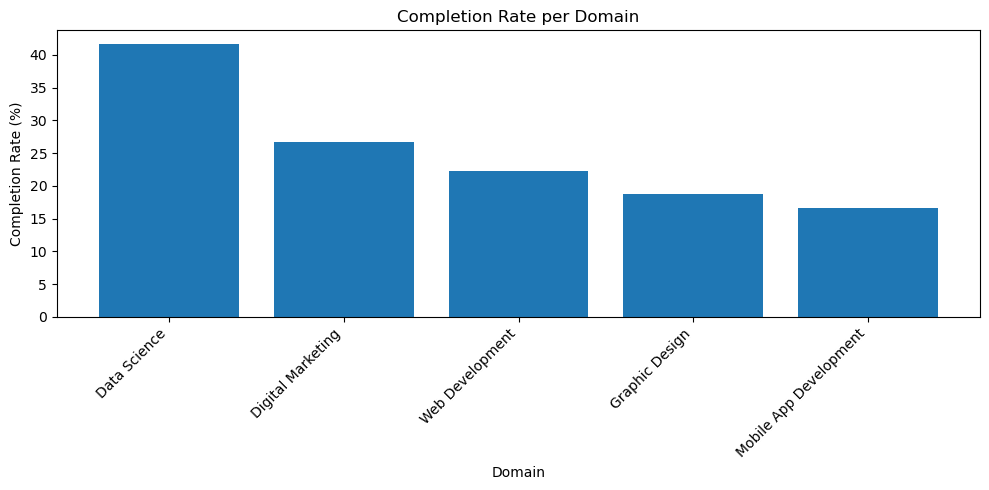

In [17]:

# Create bar chart
plt.figure(figsize=(10, 5))
plt.bar(completion_data['domain'], completion_data['completion_rate'])

plt.title("Completion Rate per Domain")
plt.xlabel("Domain")
plt.ylabel("Completion Rate (%)")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## Step 5: Analyze Average Hackathon Score per Domain

**Objective:** Calculate and visualize the average hackathon score for each domain.

**Description:** We will use the hackathon_scores table to calculate the average score of interns in each domain. The results will be displayed using a bar chart.

**Expected Outcome:** A bar chart comparing the average hackathon scores across different domains.

In [18]:
# SQL query to calculate average score
query2 = """
SELECT
    domain,
    ROUND(AVG(score), 2) AS avg_score
FROM hackathon_scores
GROUP BY domain
ORDER BY avg_score DESC;
"""

In [20]:
# Load query results
conn = sqlite3.connect("nextgen.db")
score_data = pd.read_sql_query(query2, conn)
conn.close()

In [21]:
# Apply domain filter
if selected_domain != 'All':
    score_data = score_data[
        score_data['domain'] == selected_domain
    ]

In [22]:
# Display results
display(score_data)

,domain,avg_score
0,Web Development,86.00
1,Graphic Design,76.33
2,Digital Marketing,73.67
3,Data Science,73.00
4,Mobile App Development,65.67


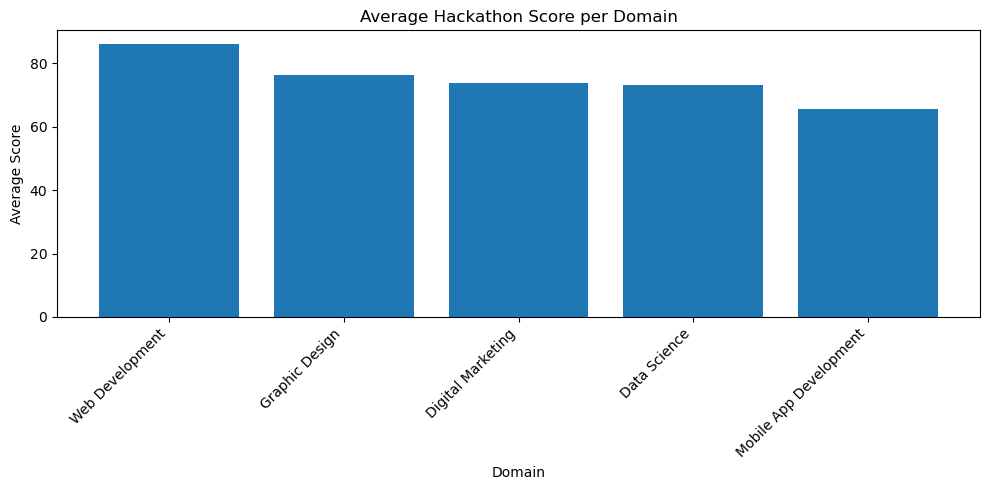

In [23]:
# Create bar chart
plt.figure(figsize=(10, 5))
plt.bar(score_data['domain'], score_data['avg_score'])

plt.title("Average Hackathon Score per Domain")
plt.xlabel("Domain")
plt.ylabel("Average Score")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## Step 6: Create Top 10 Performers Leaderboard

**Objective:** Identify and display the top 10 interns based on their hackathon scores.

**Description:** We will join the interns and hackathon_scores tables using intern_id. The records will be sorted in descending order of scores, and the top 10 performers will be selected.

**Expected Outcome:** A leaderboard displaying the top 10 interns with their IDs, domains, and hackathon scores.

In [24]:
# SQL query to get top 10 performers
query3 = """
SELECT
    i.intern_id,
    i.domain,
    h.score
FROM interns i
JOIN hackathon_scores h
    ON i.intern_id = h.intern_id
ORDER BY h.score DESC
LIMIT 10;
"""

In [25]:
# Load top 10 performers
conn = sqlite3.connect("nextgen.db")
leaderboard = pd.read_sql_query(query3, conn)
conn.close()

In [26]:
# Apply domain filter
if selected_domain != 'All':
    leaderboard = leaderboard[
        leaderboard['domain'] == selected_domain
    ]

In [27]:
# Display leaderboard
display(leaderboard)

,intern_id,domain,score
0,2003,Graphic Design,98
1,2011,Web Development,96
2,2004,Graphic Design,91
3,2015,Web Development,87
4,2022,Web Development,87
5,2007,Graphic Design,82
6,2005,Digital Marketing,80
7,2002,Data Science,76
8,2008,Data Science,74
9,2009,Web Development,74


In [28]:
import sqlite3

conn = sqlite3.connect("nextgen.db")

tables = conn.execute("""
SELECT name
FROM sqlite_master
WHERE type='table'
""").fetchall()

print("Available tables:")
for table in tables:
    print(table[0])

conn.close()

Available tables:
applicants
interns
hackathon_scores
